# AOD-Net + Laplacian pyramid fusion


In [2]:
from itertools import islice
from pathlib import Path
from tempfile import TemporaryDirectory

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


## Parameters


In [4]:
METHOD = 'laplacian_pyramid_aod_net'
LABEL = 'AOD-Net'

SOURCE = "car_008_haze_50"     # Scene name under fusion/data/
SEQ_FPS = 30.0               # FPS for image sequences
MAX_FRAMES = None            # Set to 5 for a short test
PREVIEW_FRAME = 0            # Zero-based frame index
RESIZE = 800                 # RGB dehazing long edge. Set to 0 for native resolution.

LEVELS = 5
BASE_WEIGHT = 0.6
ENERGY_KSIZE = 5

HERE = Path.cwd()
REPO_ROOT = next((p for p in (HERE, *HERE.parents)
                  if (p / "fusion" / "methods").is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open Jupyter in vidhance-extendview or its fusion/methods folder.")

DATA = REPO_ROOT / "fusion" / "data"
OUT = REPO_ROOT / "fusion" / "out"
WORK = REPO_ROOT / ".dehaze_upstream"
SCENE = DATA / SOURCE
OUTPUT = OUT / f"{METHOD}_{SOURCE}.mp4"

if MAX_FRAMES is not None and MAX_FRAMES < 1:
    raise ValueError("MAX_FRAMES must be positive or None.")


## Video I/O


In [6]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def read_image(path):
    encoded = np.fromfile(path, dtype=np.uint8)
    image = cv2.imdecode(encoded, cv2.IMREAD_COLOR) if encoded.size else None
    if image is None:
        raise ValueError(f"Could not decode image: {path}")
    return image


class FrameSource:
    """Sequential frame reader over either a video file or a directory of images (sorted by name)."""

    def __init__(self, path):
        self.path = Path(path)
        self.is_dir = self.path.is_dir()
        if self.is_dir:
            self.files = sorted(
                (p for p in self.path.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS),
                key=lambda p: p.stem.casefold(),
            )
            if not self.files:
                raise FileNotFoundError(f"no images in {self.path}")
        elif not self.path.is_file():
            raise FileNotFoundError(f"could not find video: {self.path}")

    def info(self):
        if self.is_dir:
            h, w = read_image(self.files[0]).shape[:2]
            return dict(width=w, height=h, fps=SEQ_FPS, frame_count=len(self.files))
        cap = cv2.VideoCapture(str(self.path))
        if not cap.isOpened():
            cap.release()
            raise FileNotFoundError(f"could not open video: {self.path}")
        try:
            return dict(
                width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
                fps=float(cap.get(cv2.CAP_PROP_FPS)),
                frame_count=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
            )
        finally:
            cap.release()

    def __iter__(self):
        if self.is_dir:
            for f in self.files:
                yield read_image(f)
            return
        cap = cv2.VideoCapture(str(self.path))
        try:
            while True:
                ok, frame = cap.read()
                if not ok:
                    return
                yield frame
        finally:
            cap.release()

    def read(self, index):
        if self.is_dir:
            return read_image(self.files[index])
        cap = cv2.VideoCapture(str(self.path))
        cap.set(cv2.CAP_PROP_POS_FRAMES, index)
        ok, frame = cap.read()
        cap.release()
        if not ok:
            raise IndexError(f"no frame {index} in {self.path}")
        return frame


def pick(video_name, directory_name):
    video, directory = SCENE / video_name, SCENE / directory_name
    if video.is_file():
        return video
    if directory.is_dir():
        return directory
    raise FileNotFoundError(f"Missing input: {video} or {directory}")


visible = FrameSource(pick("visible.mp4", "rgb"))
thermal = FrameSource(pick("thermal.mp4", "ir"))
info_v, info_t = visible.info(), thermal.info()
width, height = info_v["width"], info_v["height"]
if (width, height) != (info_t["width"], info_t["height"]):
    raise ValueError("Visible and infrared frames must have the same resolution.")

if visible.is_dir and thermal.is_dir:
    vis_keys = [p.stem.casefold() for p in visible.files]
    ir_keys = [p.stem.casefold() for p in thermal.files]
    if vis_keys != ir_keys or len(set(vis_keys)) != len(vis_keys):
        raise ValueError("rgb/ and ir/ must contain one frame per matching filename stem.")

if not np.isfinite(info_v["fps"]) or info_v["fps"] <= 0:
    raise ValueError("The visible input has no usable frame rate.")

print(f"{SOURCE} | {width}x{height} | {info_v['fps']:.2f} fps")


def iter_frame_pairs():
    for frame_v, frame_t in zip(visible, thermal):
        if frame_v.shape[:2] != (height, width) or frame_t.shape[:2] != (height, width):
            raise ValueError("Input frame sizes changed or do not match.")
        yield frame_v, frame_t


car_008_haze_50 | 1920x1080 | 30.00 fps


## Pretrained weights
Select `public` or `team`, or set `CHECKPOINT` to a local `.pth` file.


In [8]:
WEIGHTS = "public"         # "public" or "team"
CHECKPOINT = None          # Optional path to a local AOD-Net .pth file

import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device: {DEVICE}")

from urllib.request import urlopen
from shutil import copyfileobj


def fetch_upstream(repo, revision, files):
    """Cache only the files needed from the pinned upstream revision."""
    root = WORK / 'upstream' / f"{repo.replace('/', '--')}-{revision[:8]}"
    base = f'https://raw.githubusercontent.com/{repo}/{revision}'
    for name in files:
        target = root / name
        if target.is_file() and target.stat().st_size > 0:
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        pending = target.with_name(target.name + '.part')
        try:
            with urlopen(f'{base}/{name}', timeout=90) as source, pending.open('wb') as output:
                copyfileobj(source, output)
            pending.replace(target)
        except OSError as error:
            raise RuntimeError(f'无法获取 {repo}/{name}。请检查网络，或在 CHECKPOINT 设置本地权重路径。') from error
        finally:
            pending.unlink(missing_ok=True)
    return root


if CHECKPOINT is not None:
    CKPT = Path(CHECKPOINT)
elif WEIGHTS == "public":
    model_dir = fetch_upstream(
        "TheFairBear/PyTorch-Image-Dehazing", "dc26717cde24748e27ffc9d050564e295654b90d",
        ("snapshots/dehazer.pth",),
    )
    CKPT = model_dir / "snapshots" / "dehazer.pth"
elif WEIGHTS == "team":
    CKPT = REPO_ROOT / "checkpoints" / "aod_net_best.pth"
else:
    raise ValueError("WEIGHTS must be 'public' or 'team'.")
if not CKPT.is_file():
    raise FileNotFoundError(f"Set CHECKPOINT to an AOD-Net weights file. Checked: {CKPT}")
print("Weights:", CKPT)


PyTorch 2.8.0+cpu | Device: cpu
Weights: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\.dehaze_upstream\upstream\TheFairBear--PyTorch-Image-Dehazing-dc26717c\snapshots\dehazer.pth


## Model


In [10]:
class AODNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.relu = nn.ReLU(inplace=True)
        self.conv1 = nn.Conv2d(3, 3, kernel_size=1, padding=0)
        self.conv2 = nn.Conv2d(3, 3, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(6, 3, kernel_size=5, padding=2)
        self.conv4 = nn.Conv2d(6, 3, kernel_size=7, padding=3)
        self.conv5 = nn.Conv2d(12, 3, kernel_size=3, padding=1)
        self.b = 1.0

    def forward(self, x):
        x1 = self.relu(self.conv1(x))
        x2 = self.relu(self.conv2(x1))
        x3 = self.relu(self.conv3(torch.cat([x1, x2], dim=1)))
        x4 = self.relu(self.conv4(torch.cat([x2, x3], dim=1)))
        k = self.relu(self.conv5(torch.cat([x1, x2, x3, x4], dim=1)))   # K(x)
        return torch.clamp(self.relu(k * x - k + self.b), 0, 1)       # J = K*I - K + b


net = AODNet()
state = torch.load(CKPT, map_location="cpu", weights_only=True)
for key in ("state_dict", "model", "params", "net"):
    if isinstance(state, dict) and isinstance(state.get(key), dict):
        state = state[key]
        break
state = {k.removeprefix("module.").replace("e_conv", "conv"): v for k, v in state.items()}
net.load_state_dict(state, strict=True)
net = net.to(DEVICE).eval()
print(f"AOD-Net loaded: {sum(p.numel() for p in net.parameters())} params")


AOD-Net loaded: 1761 params


## Method


In [12]:
def dehaze(hazy):
    """PIL RGB image to float RGB in [0, 1]."""
    x = torch.from_numpy(np.asarray(hazy, dtype=np.float32) / 255).permute(2, 0, 1)[None].to(DEVICE)
    return net(x)[0].permute(1, 2, 0).cpu().numpy()


def to_gray01(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0


def fuse(visible_bgr, thermal_bgr):
    """Fuse only the luminance (Y) channel; keep the visible image's colour (CrCb)."""
    ycc = cv2.cvtColor(visible_bgr, cv2.COLOR_BGR2YCrCb).astype(np.float32) / 255.0
    ycc[..., 0] = fuse_gray(ycc[..., 0], to_gray01(thermal_bgr))
    return cv2.cvtColor((np.clip(ycc, 0, 1) * 255).astype(np.uint8), cv2.COLOR_YCrCb2BGR)


def gaussian_pyramid(img, levels):
    pyr = [img]
    for _ in range(levels):
        pyr.append(cv2.pyrDown(pyr[-1]))
    return pyr


def laplacian_pyramid(img, levels):
    g = gaussian_pyramid(img, levels)
    lap = []
    for i in range(levels):
        up = cv2.pyrUp(g[i + 1], dstsize=(g[i].shape[1], g[i].shape[0]))
        lap.append(g[i] - up)
    lap.append(g[-1])  # low-pass base
    return lap


def collapse(lap):
    img = lap[-1]
    for band in reversed(lap[:-1]):
        img = cv2.pyrUp(img, dstsize=(band.shape[1], band.shape[0])) + band
    return img


def fuse_gray(yv, t):
    lv, lt = laplacian_pyramid(yv, LEVELS), laplacian_pyramid(t, LEVELS)
    fused = []
    k = (ENERGY_KSIZE, ENERGY_KSIZE)
    for a, b in zip(lv[:-1], lt[:-1]):
        ea, eb = cv2.GaussianBlur(np.abs(a), k, 0), cv2.GaussianBlur(np.abs(b), k, 0)
        fused.append(np.where(ea >= eb, a, b))  # choose-max on local detail energy
    fused.append(BASE_WEIGHT * lv[-1] + (1 - BASE_WEIGHT) * lt[-1])
    return np.clip(collapse(fused), 0, 1)


def restore_and_fuse(visible_bgr, thermal_bgr):
    """Dehaze visible RGB, then fuse its Y with IR and reuse its Cr/Cb."""
    hazy = Image.fromarray(cv2.cvtColor(visible_bgr, cv2.COLOR_BGR2RGB))
    source_size = hazy.size
    if RESIZE > 0 and max(source_size) > RESIZE:
        scale = RESIZE / max(source_size)
        size = tuple(max(1, round(v * scale)) for v in source_size)
        hazy = hazy.resize(size, Image.Resampling.BICUBIC)

    with torch.inference_mode():
        prediction = dehaze(hazy)
    if prediction.shape != (hazy.height, hazy.width, 3) or not np.isfinite(prediction).all():
        raise ValueError(f"{LABEL}: invalid RGB prediction with shape {prediction.shape}.")

    rgb = np.rint(np.clip(prediction, 0, 1) * 255).astype(np.uint8)
    restored = Image.fromarray(rgb)
    if restored.size != source_size:
        restored = restored.resize(source_size, Image.Resampling.BICUBIC)
    restored_bgr = cv2.cvtColor(np.asarray(restored), cv2.COLOR_RGB2BGR)
    return restored_bgr, fuse(restored_bgr, thermal_bgr)


## Preview a single frame


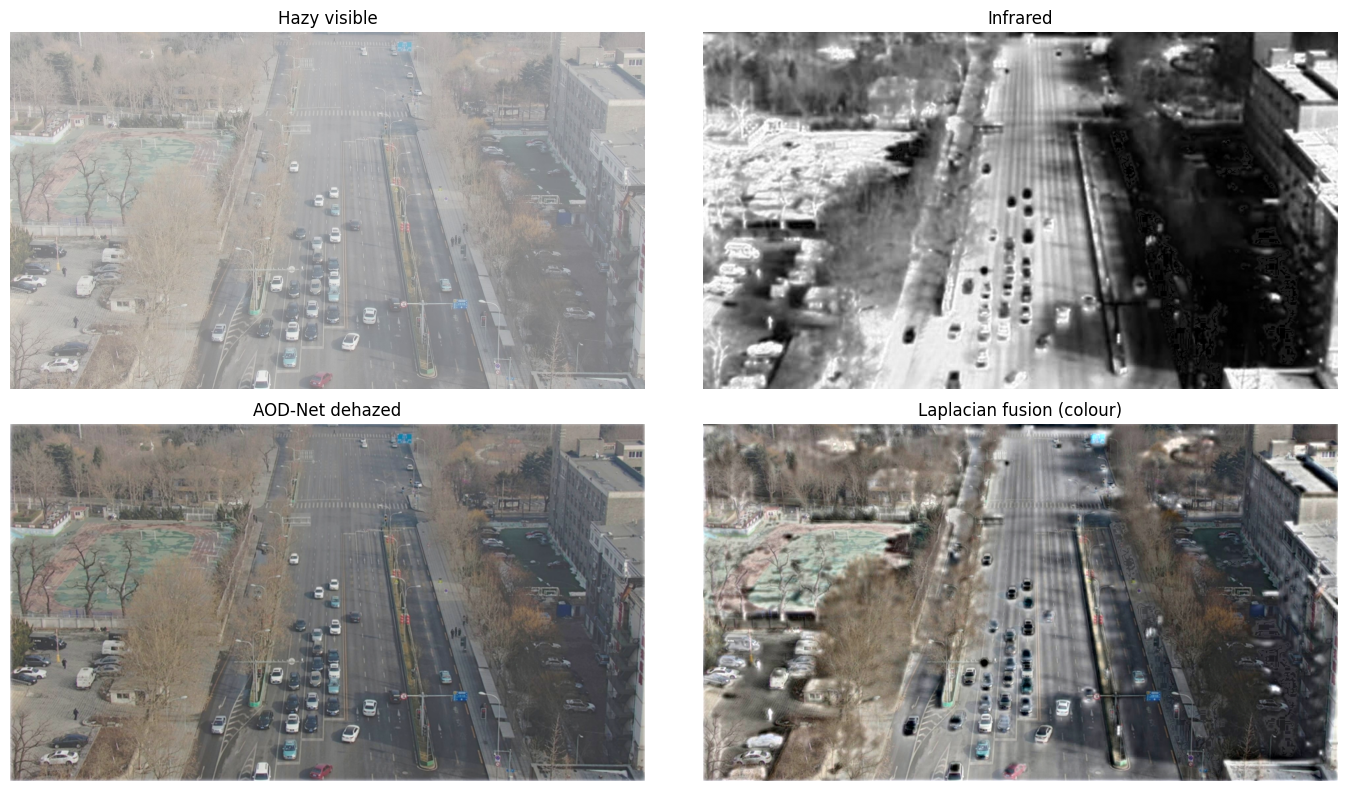

In [14]:
v, t = visible.read(PREVIEW_FRAME), thermal.read(PREVIEW_FRAME)
restored, fused = restore_and_fuse(v, t)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
panels = (
    ("Hazy visible", cv2.cvtColor(v, cv2.COLOR_BGR2RGB)),
    ("Infrared", cv2.cvtColor(t, cv2.COLOR_BGR2GRAY)),
    (f"{LABEL} dehazed", cv2.cvtColor(restored, cv2.COLOR_BGR2RGB)),
    ("Laplacian fusion (colour)", cv2.cvtColor(fused, cv2.COLOR_BGR2RGB)),
)
for ax, (title, image) in zip(axes.flat, panels):
    if image.ndim == 2:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.show()


## Run over the whole video


In [16]:
if width % 2 or height % 2:
    raise ValueError("Use even-width and even-height source frames for MP4 output.")

OUTPUT.parent.mkdir(parents=True, exist_ok=True)
counts = [n for n in (info_v["frame_count"], info_t["frame_count"]) if n > 0]
if MAX_FRAMES is not None:
    counts.append(MAX_FRAMES)
total = min(counts) if counts else "?"

# Publish the video only after closing the writer successfully.
with TemporaryDirectory(prefix=f".{METHOD}-", dir=OUTPUT.parent) as temporary:
    pending = Path(temporary) / OUTPUT.name
    writer = cv2.VideoWriter(str(pending), cv2.VideoWriter_fourcc(*"mp4v"),
                             info_v["fps"], (width, height))
    written = 0
    try:
        if not writer.isOpened():
            raise RuntimeError(f"Could not open the MP4 writer: {pending}")
        for frame_v, frame_t in islice(iter_frame_pairs(), MAX_FRAMES):
            _, fused = restore_and_fuse(frame_v, frame_t)
            writer.write(fused)
            written += 1
            if written % 50 == 0 or written == total:
                print(f"{written}/{total} frames")
    finally:
        writer.release()
    if written == 0:
        raise RuntimeError("The visible/infrared pair did not contain any readable frames.")
    pending.replace(OUTPUT)

print(f"Wrote {written} colour frames to {OUTPUT}")


5/5 frames
Wrote 5 colour frames to C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\fusion\out\laplacian_pyramid_aod_net_car_008_haze_50.mp4
